In [2]:
import yfinance as yf
import pandas as pd

# Descargar datos de AAPL desde Yahoo Finance
data = yf.download('AAPL', start='2010-01-01', end='2022-01-01')

# Mostrar las primeras filas del DataFrame
data.head()

[*********************100%%**********************]  1 of 1 completed


/home/suarenguen/anaconda3/lib/python3.11/site-packages/yfinance/utils.py:788: FutureWarning: The 'unit' keyword in TimedeltaIndex construction is deprecated and will be removed in a future version. Use pd.to_timedelta instead.
  df.index += _pd.TimedeltaIndex(dst_error_hours, 'h')


,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2010-01-04,7.622500,7.660714,7.585000,7.643214,6.454506,493729600
2010-01-05,7.664286,7.699643,7.616071,7.656429,6.465665,601904800
2010-01-06,7.656429,7.686786,7.526786,7.534643,6.362820,552160000
2010-01-07,7.562500,7.571429,7.466071,7.520714,6.351058,477131200
2010-01-08,7.510714,7.571429,7.466429,7.570714,6.393281,447610800


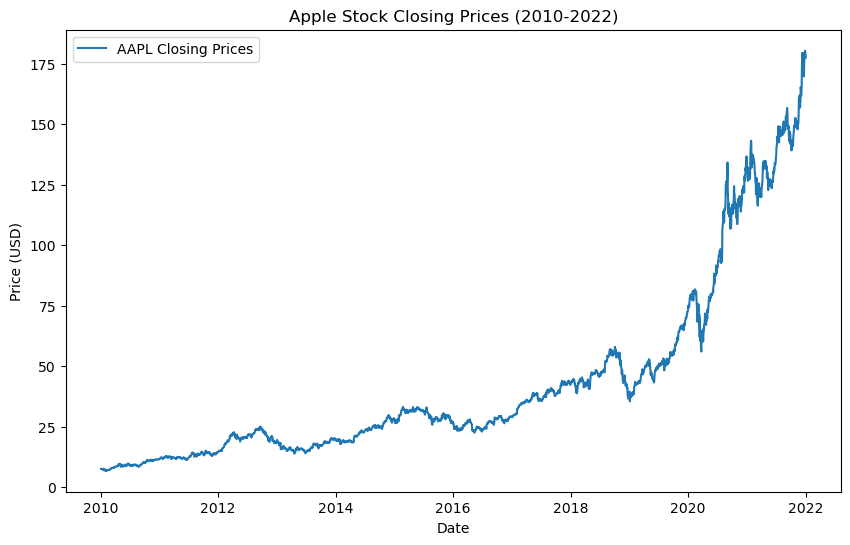

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(data['Close'], label='AAPL Closing Prices')
plt.title('Apple Stock Closing Prices (2010-2022)')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.show()

In [4]:
mean_price = data['Close'].mean()
std_price = data['Close'].std()

print(f"Mean Price: {mean_price}")
print(f"Standard Deviation: {std_price}")

Mean Price: 42.72072799282333
Standard Deviation: 38.084410458575185


In [5]:
import numpy as np

def create_sequences(data, time_steps=60):
    sequences = []
    targets = []
    for i in range(len(data) - time_steps):
        sequences.append(data[i:i + time_steps])
        targets.append(data[i + time_steps])
    return np.array(sequences), np.array(targets)

# Crear secuencias y objetivos
close_prices = data['Close'].values
X, y = create_sequences(close_prices, 60)

In [6]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
close_prices_scaled = scaler.fit_transform(close_prices.reshape(-1, 1))

# Crear secuencias con los precios normalizados
X_scaled, y_scaled = create_sequences(close_prices_scaled, 60)

In [7]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

# Definir el modelo RNN
rnn_model = Sequential()
rnn_model.add(SimpleRNN(units=5, activation='relu', return_sequences=False, input_shape=(60, 1)))
rnn_model.add(Dense(units=1))

rnn_model.compile(optimizer='adam', loss='mean_squared_error')

2024-09-06 14:00:58.520340: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-09-06 14:01:01.067347: I tensorflow/core/common_runtime/process_util.cc:146] Creating new thread pool with default inter op setting: 2. Tune using inter_op_parallelism_threads for best performance.


In [8]:
from tensorflow.keras.layers import LSTM

# Definir el modelo LSTM
lstm_model = Sequential()
lstm_model.add(LSTM(units=5, activation='relu', return_sequences=False, input_shape=(60, 1)))
lstm_model.add(Dense(units=1))

lstm_model.compile(optimizer='adam', loss='mean_squared_error')

In [9]:
# Dividir los datos en conjunto de entrenamiento y prueba
split = int(0.8 * len(X_scaled))
X_train, X_test = X_scaled[:split], X_scaled[split:]
y_train, y_test = y_scaled[:split], y_scaled[split:]

# Entrenar el modelo RNN
rnn_history = rnn_model.fit(X_train, y_train, epochs=5, batch_size=16)

# Entrenar el modelo LSTM
lsm_history = lstm_model.fit(X_train, y_train, epochs=5, batch_size=16)

Epoch 1/5


2024-09-06 14:01:02.312540: W tensorflow/core/grappler/utils/graph_view.cc:849] No registered '' OpKernel for CPU devices compatible with node {{node sequential/simple_rnn/while/body/_1/sequential/simple_rnn/while/simple_rnn_cell/Relu}}
	.  Registered:  <no registered kernels>

2024-09-06 14:01:02.345935: E tensorflow/core/grappler/optimizers/tfg_optimizer_hook.cc:134] tfg_optimizer{any(tfg-consolidate-attrs,tfg-toposort,tfg-shape-inference{graph-version=0},tfg-prepare-attrs-export)} failed: INVALID_ARGUMENT: Node sequential/simple_rnn/while/body/_1/sequential/simple_rnn/while/simple_rnn_cell/Relu has an empty op name
	when importing GraphDef to MLIR module in GrapplerHook
2024-09-06 14:01:02.386441: E tensorflow/core/grappler/optimizers/tfg_optimizer_hook.cc:134] tfg_optimizer{any(tfg-consolidate-attrs,tfg-functional-to-region,tfg.func(tfg-cf-sink),tfg-region-to-functional{force-control-capture=true},tfg-lift-legacy-call,symbol-privatize{},symbol-dce,tfg-prepare-attrs-export)} failed:

148/148 [==============================] - 3s 11ms/step - loss: 0.0364
Epoch 2/5
148/148 [==============================] - 2s 10ms/step - loss: 0.0086
Epoch 3/5
148/148 [==============================] - 2s 12ms/step - loss: 0.0063
Epoch 4/5
148/148 [==============================] - 2s 11ms/step - loss: 0.0055
Epoch 5/5
148/148 [==============================] - 1s 8ms/step - loss: 0.0052
Epoch 1/5
148/148 [==============================] - 3s 13ms/step - loss: 0.0090
Epoch 2/5
148/148 [==============================] - 2s 13ms/step - loss: 0.0052
Epoch 3/5
148/148 [==============================] - 2s 16ms/step - loss: 0.0051
Epoch 4/5
148/148 [==============================] - 3s 18ms/step - loss: 0.0051
Epoch 5/5
148/148 [==============================] - 2s 15ms/step - loss: 0.0051


In [10]:
rnn_loss = rnn_model.evaluate(X_test, y_test)
lstm_loss = lstm_model.evaluate(X_test, y_test)

print(f"RNN Test Loss: {rnn_loss}")
print(f"LSTM Test Loss: {lstm_loss}")

19/19 [==============================] - 1s 21ms/step - loss: 0.2686
RNN Test Loss: 0.5683432817459106
LSTM Test Loss: 0.26857349276542664


dict_keys(['loss'])
dict_keys(['loss'])


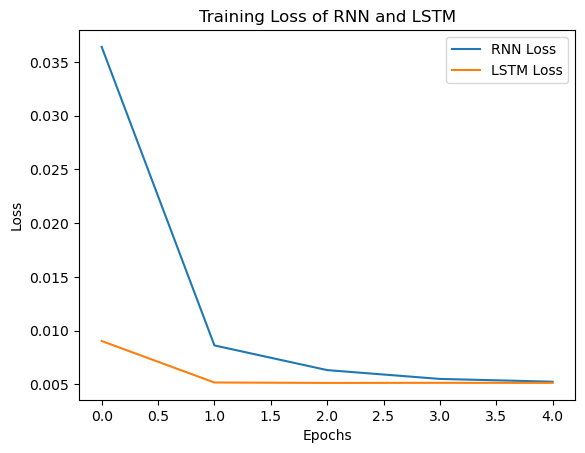

In [11]:
# Verificar si 'loss' está disponible en el historial
print(rnn_history.history.keys())
print(lsm_history.history.keys())

# Graficar las pérdidas de entrenamiento
plt.plot(rnn_history.history['loss'], label='RNN Loss')
plt.plot(lsm_history.history['loss'], label='LSTM Loss')
plt.legend()
plt.title('Training Loss of RNN and LSTM')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.show()

In [12]:
# # Importar las librerías necesarias
# import numpy as np
# from scikeras.wrappers import KerasRegressor
# from sklearn.model_selection import GridSearchCV
# from tensorflow.keras.models import Sequential
# from tensorflow.keras.layers import LSTM, Dense
# from tensorflow.keras.optimizers import Adam

# # Función para crear el modelo de Keras
# def build_lstm_model(units=50, learning_rate=0.001):
#     model = Sequential()
#     model.add(LSTM(units=units, activation='relu', input_shape=(60, 1)))
#     model.add(Dense(units=1))
#     optimizer = Adam(learning_rate=learning_rate)  # Usamos la tasa de aprendizaje pasada
#     model.compile(optimizer=optimizer, loss='mean_squared_error')
#     return model

# # Envolver el modelo con Scikeras KerasRegressor
# lstm_model = KerasRegressor(model=build_lstm_model, verbose=1)

# # Definir el espacio de búsqueda de hiperparámetros
# param_grid = {
#     'model__units': [50, 100],              # Número de unidades LSTM
#     'batch_size': [32, 64],                 # Tamaños de batch
#     'epochs': [10, 20],                     # Número de épocas
#     'model__learning_rate': [0.001, 0.01]   # Tasa de aprendizaje
# }

# # Realizar la búsqueda de hiperparámetros con GridSearchCV
# grid = GridSearchCV(estimator=lstm_model, param_grid=param_grid, scoring='neg_mean_squared_error', cv=3)

# # Ajustar el GridSearchCV a los datos de entrenamiento
# grid_result = grid.fit(X_train, y_train)

# # Mostrar los mejores hiperparámetros encontrados
# print("Best Hyperparameters: ", grid_result.best_params_)

# # Evaluar el mejor modelo en el conjunto de prueba
# best_model = grid_result.best_estimator_
# test_loss = best_model.score(X_test, y_test)
# print(f"Test Loss of the Best Model: {test_loss}")

In [13]:
# Best Hyperparameters:  {'batch_size': 32, 'epochs': 20, 'model__learning_rate': 0.001, 'model__units': 100}
# 19/19 [==============================] - 2s 90ms/step
# Test Loss of the Best Model: 0.9841624150256233

In [ ]:
from scikeras.wrappers import KerasRegressor
from sklearn.model_selection import GridSearchCV
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.optimizers import Adam

def build_lstm_model(units=30, learning_rate=0.001):  # Reducción de unidades
    model = Sequential()
    model.add(LSTM(units=units, activation='relu', input_shape=(60, 1)))
    model.add(Dense(units=1))
    # optimizer = Adam(learning_rate=learning_rate)
    model.compile(optimizer='adam', loss='mean_squared_error')
    return model

# Envolver el modelo para usar con Scikit-learn
lstm_model = KerasRegressor(model=build_lstm_model, verbose=1)

param_grid = {
    'model__units': [10, 20, 50],  
    'batch_size': [16, 32],
    'epochs': [5, 10],
    # 'model__learning_rate': [0.001] 
}

# Configuración de GridSearchCV con menos CV y un grid más simple
grid = GridSearchCV(estimator=lstm_model, param_grid=param_grid, scoring='neg_mean_squared_error', cv=2)

# Ajustar el modelo
grid_result = grid.fit(X_train, y_train)

# Mostrar los resultados
print("Best Hyperparameters: ", grid_result.best_params_)
best_model = grid_result.best_estimator_
test_loss = best_model.score(X_test, y_test)
print(f"Test Loss of the Best Model: {test_loss}")

Epoch 1/5
74/74 [==============================] - 3s 13ms/step - loss: 0.0081
Epoch 2/5
74/74 [==============================] - 1s 14ms/step - loss: 4.5965e-04
Epoch 3/5
74/74 [==============================] - 1s 15ms/step - loss: 6.7540e-05
Epoch 4/5
74/74 [==============================] - 1s 15ms/step - loss: 4.8488e-05
Epoch 5/5
74/74 [==============================] - 1s 7ms/step
Epoch 1/5
74/74 [==============================] - 3s 16ms/step - loss: 3.6345e-04
Epoch 2/5
74/74 [==============================] - 1s 18ms/step - loss: 1.8535e-05
Epoch 3/5
74/74 [==============================] - 1s 18ms/step - loss: 1.6383e-05
Epoch 4/5
74/74 [==============================] - 1s 10ms/step - loss: 1.6409e-05
Epoch 5/5
74/74 [==============================] - 1s 5ms/step
Epoch 1/5
74/74 [==============================] - 2s 11ms/step - loss: 0.0052
Epoch 2/5
74/74 [==============================] - 1s 12ms/step - loss: 6.2959e-04
Epoch 3/5
74/74 [==============================] - 1